

```
# This is formatted as code
```

#  Persiapan & Validasi Data
**Tujuan:** memastikan data benar-benar dapat dipercaya sebelum dianalisis. Analis yang baik tidak langsung membuat grafik — ia membuktikan dulu bahwa angkanya konsisten.

Yang dikerjakan: (1) memuat 7 sheet, (2) cek struktur, (3) hitung ulang kolom turunan, (4) cek konsistensi antar tabel, (5) deteksi nilai ekstrem, (6) ringkasan hasil.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from matplotlib.ticker import FuncFormatter

pd.set_option("display.width", 140, "display.max_columns", 30)
XLSX = "Smelter_Data_Lanjutan.xlsx"

# Di Google Colab: jika berkas belum ada, tampilkan dialog unggah.
try:
    from google.colab import files          # hanya ada di Colab
    if not os.path.exists(XLSX):
        files.upload()                      # pilih Smelter_Data_Lanjutan.xlsx
except ImportError:
    pass

sheets = pd.read_excel(XLSX, sheet_name=None)           # dict: nama sheet -> DataFrame
for nama, df in sheets.items():
    print(f"{nama:16s} {df.shape[0]:>4} baris x {df.shape[1]:>2} kolom")

Kunci_Simulasi      7 baris x  4 kolom
Data_Harian       273 baris x 17 kolom
Downtime_Log       73 baris x  6 kolom
QC_Lab            273 baris x  7 kolom
Proses_Harian     273 baris x  8 kolom
Produksi_Shift    819 baris x  8 kolom
Harga_Biaya       273 baris x  6 kolom
Komponen_Kritis    44 baris x  8 kolom


`sheet_name=None` membaca **semua** sheet sekaligus ke dalam kamus (dict). Sheet `Kunci_Simulasi` berisi catatan mana tabel asli dan mana simulasi.

In [ ]:
print(sheets["Kunci_Simulasi"].to_string(index=False))
harian = sheets["Data_Harian"]; log = sheets["Downtime_Log"]; qc = sheets["QC_Lab"]
proses = sheets["Proses_Harian"]; shift = sheets["Produksi_Shift"]
for df in (harian, log, qc, proses, shift):
    df["Tanggal"] = pd.to_datetime(df["Tanggal"])

          Sheet   Status  Baris                                                                                                                              Catatan
    Data_Harian     ASLI    273                                                                                              Harian 1 Jan-30 Sep 2026 (tidak diubah)
   Downtime_Log     ASLI     73                                                                                                     Kejadian downtime (tidak diubah)
         QC_Lab     ASLI    273                                                                                                              Batch QC (tidak diubah)
  Proses_Harian SIMULASI    273                       Sensor proses harian. Dibangkitkan berkorelasi dengan Energi/t dan Recovery agar regresi bermakna (seed 2026).
 Produksi_Shift SIMULASI    819                                             3 shift/hari. Jumlah Katoda, Energi, Jam_Downtime per hari = Data_Harian PERSIS (dicek).
    Harga_

## 1. Cek struktur: tipe data, nilai kosong, duplikat, kelengkapan tanggal

In [ ]:
hasil = []                                    # kumpulan hasil cek: (nama cek, lolos?, detail)
def cek(nama, kondisi, detail=""):
    hasil.append((nama, bool(kondisi), detail)); print(("LOLOS " if kondisi else "GAGAL ") + nama, detail)

for nama in ["Data_Harian", "Downtime_Log", "QC_Lab", "Proses_Harian", "Produksi_Shift"]:
    df = sheets[nama]
    cek(f"{nama}: tidak ada nilai kosong", df.isna().sum().sum() == 0, f"(kosong={df.isna().sum().sum()})")
    cek(f"{nama}: tidak ada baris duplikat", df.duplicated().sum() == 0)

rentang = pd.date_range(harian.Tanggal.min(), harian.Tanggal.max(), freq="D")
cek("Data_Harian: tanggal lengkap & unik tanpa lubang", len(rentang) == len(harian) == harian.Tanggal.nunique(), f"({len(rentang)} hari)")
cek("Produksi_Shift: tepat 3 shift per hari", (shift.groupby("Tanggal").size() == 3).all())

LOLOS Data_Harian: tidak ada nilai kosong (kosong=0)
LOLOS Data_Harian: tidak ada baris duplikat 
LOLOS Downtime_Log: tidak ada nilai kosong (kosong=0)
LOLOS Downtime_Log: tidak ada baris duplikat 
LOLOS QC_Lab: tidak ada nilai kosong (kosong=0)
LOLOS QC_Lab: tidak ada baris duplikat 
LOLOS Proses_Harian: tidak ada nilai kosong (kosong=0)
LOLOS Proses_Harian: tidak ada baris duplikat 
LOLOS Produksi_Shift: tidak ada nilai kosong (kosong=0)
LOLOS Produksi_Shift: tidak ada baris duplikat 
LOLOS Data_Harian: tanggal lengkap & unik tanpa lubang (273 hari)
LOLOS Produksi_Shift: tepat 3 shift per hari 


## 2. Hitung ulang kolom turunan
Kolom seperti *Recovery* dan *Availability* adalah hasil rumus. Kita hitung ulang sendiri dan bandingkan. Selisih besar = ada kolom yang salah atau rumusnya berbeda dari yang kita kira.

In [ ]:
h = harian
rumus = {
    "Cu_Masuk_t": h.Konsentrat_Masuk_DMT * h.Cu_Grade_Persen / 100,
    "Recovery_Persen": h.Katoda_Cu_t / h.Cu_Masuk_t * 100,
    "Availability_Persen": h.Jam_Operasi / 24 * 100,
    "Energi_per_t_Katoda_MWh": h.Energi_MWh / h.Katoda_Cu_t,
    "Rasio_Asam_per_Konsentrat": h.Asam_Sulfat_t / h.Konsentrat_Masuk_DMT,
}
for kol, hitung in rumus.items():
    selisih = (hitung - h[kol]).abs().max()
    cek(f"Rumus {kol} cocok", selisih < 1e-6, f"(selisih maks={selisih:.2e})")
cek("Jam_Operasi + Jam_Downtime = 24", np.allclose(h.Jam_Operasi + h.Jam_Downtime, 24))

LOLOS Rumus Cu_Masuk_t cocok (selisih maks=1.14e-13)
LOLOS Rumus Recovery_Persen cocok (selisih maks=8.53e-14)
LOLOS Rumus Availability_Persen cocok (selisih maks=4.26e-14)
LOLOS Rumus Energi_per_t_Katoda_MWh cocok (selisih maks=5.11e-15)
LOLOS Rumus Rasio_Asam_per_Konsentrat cocok (selisih maks=5.55e-16)
LOLOS Jam_Operasi + Jam_Downtime = 24 


## 3. Konsistensi antar tabel (rekonsiliasi)
Total di satu tabel harus sama dengan jumlah rinciannya di tabel lain.

In [ ]:
dt_harian = log.groupby("Tanggal").Durasi_Jam.sum()
gabung = harian.set_index("Tanggal").Jam_Downtime.to_frame().join(dt_harian.rename("dari_log")).fillna({"dari_log": 0})
cek("Downtime_Log dijumlah per hari = Jam_Downtime harian", np.allclose(gabung.Jam_Downtime, gabung.dari_log),
    f"(total {gabung.Jam_Downtime.sum():.1f} jam vs {gabung.dari_log.sum():.1f} jam)")

sh = shift.groupby("Tanggal")[["Katoda_Cu_t", "Energi_MWh", "Jam_Downtime"]].sum()
hh = harian.set_index("Tanggal")
for kol in ["Katoda_Cu_t", "Energi_MWh", "Jam_Downtime"]:
    cek(f"Produksi_Shift dijumlah per hari = {kol} harian", np.allclose(sh[kol], hh[kol], atol=1e-6))
cek("QC_Lab: 1 batch per hari, tanggal sama dengan harian", set(qc.Tanggal) == set(harian.Tanggal) and qc.Tanggal.is_unique)
cek("Status_Mutu hanya Grade A / Off-grade", set(qc.Status_Mutu) <= {"Grade A", "Off-grade"})
cek("Tanggal Downtime_Log berada dalam rentang harian", log.Tanggal.between(harian.Tanggal.min(), harian.Tanggal.max()).all())

LOLOS Downtime_Log dijumlah per hari = Jam_Downtime harian (total 329.5 jam vs 329.5 jam)
LOLOS Produksi_Shift dijumlah per hari = Katoda_Cu_t harian 
LOLOS Produksi_Shift dijumlah per hari = Energi_MWh harian 
LOLOS Produksi_Shift dijumlah per hari = Jam_Downtime harian 
LOLOS QC_Lab: 1 batch per hari, tanggal sama dengan harian 
LOLOS Status_Mutu hanya Grade A / Off-grade 
LOLOS Tanggal Downtime_Log berada dalam rentang harian 


## 4. Nilai ekstrem (metode IQR) pada kolom utama
Pagar Tukey: nilai di luar `Q1 - 1.5*IQR` atau `Q3 + 1.5*IQR` ditandai. **Ditandai bukan berarti salah** — keputusan membuang/mempertahankan butuh konteks proses.

                             min    median      maks  n_ekstrem_IQR
Konsentrat_Masuk_DMT     784.000  2354.000  2496.000             39
Cu_Grade_Persen           23.500    25.680    27.500              0
Katoda_Cu_t              205.100   595.500   662.500             28
Energi_MWh               363.000   858.000  1016.000             22
Recovery_Persen           90.005    98.267    99.201              5
Energi_per_t_Katoda_MWh    1.363     1.468     1.770              4


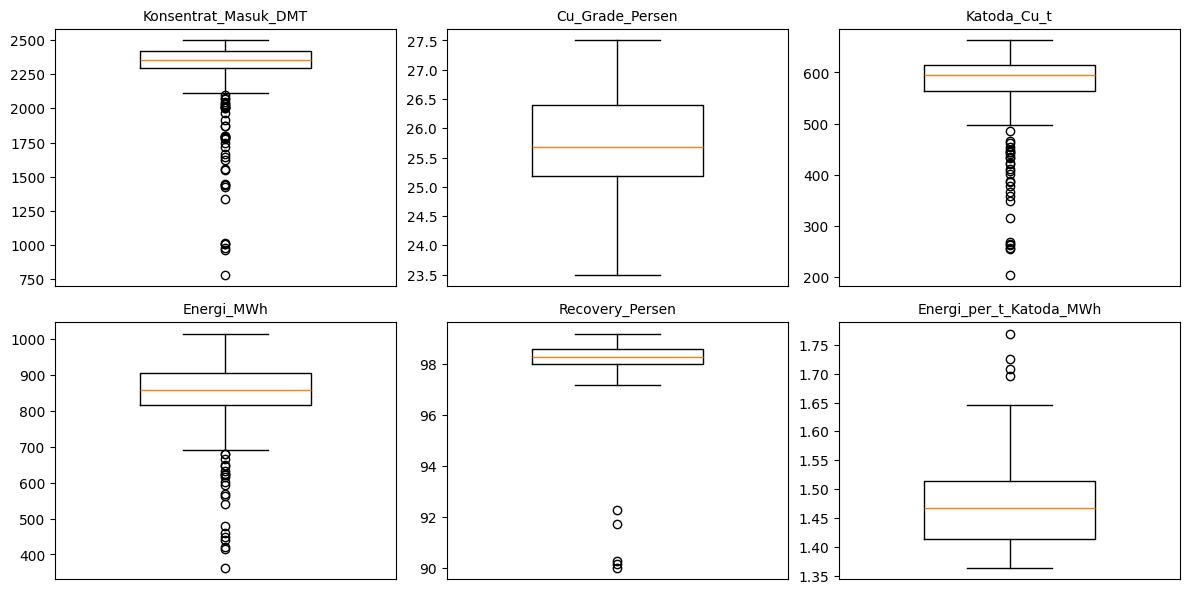

In [ ]:
def ekstrem(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()
kolom = ["Konsentrat_Masuk_DMT", "Cu_Grade_Persen", "Katoda_Cu_t", "Energi_MWh", "Recovery_Persen", "Energi_per_t_Katoda_MWh"]
tabel = pd.DataFrame({"min": harian[kolom].min(), "median": harian[kolom].median(), "maks": harian[kolom].max(),
                      "n_ekstrem_IQR": [ekstrem(harian[k]) for k in kolom]})
print(tabel.round(3))

fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for a, k in zip(ax.ravel(), kolom):
    a.boxplot(harian[k], widths=.5); a.set_title(k, fontsize=10); a.set_xticks([])
plt.tight_layout(); plt.show()

## 5. Rentang wajar (aturan bisnis)

In [ ]:
cek("Recovery dalam batas fisik 80–100%", harian.Recovery_Persen.between(80, 100).all())
# Batas "normal operasi" 95% hanya peringatan, bukan kesalahan data:
rendah = harian[harian.Recovery_Persen < 95][["Tanggal", "Jam_Downtime", "Recovery_Persen"]]
print(f"\nTEMUAN: {len(rendah)} hari recovery < 95% (nilai asli, bukan salah ketik) -> diselidiki di Fase 2 (deteksi anomali):")
print(rendah.to_string(index=False, float_format="%.2f"))
cek("Grade Cu konsentrat 20–32%", harian.Cu_Grade_Persen.between(20, 32).all())
cek("Durasi downtime > 0", (log.Durasi_Jam > 0).all())
cek("Pb/S/Fe ppm tidak negatif", (qc[["Pb_ppm", "S_ppm", "Fe_ppm"]] >= 0).all().all())

LOLOS Recovery dalam batas fisik 80–100% 

TEMUAN: 5 hari recovery < 95% (nilai asli, bukan salah ketik) -> diselidiki di Fase 2 (deteksi anomali):
   Tanggal  Jam_Downtime  Recovery_Persen
2026-01-08          0.00            91.73
2026-03-05          0.00            90.26
2026-03-28          4.00            90.01
2026-06-05          0.00            90.16
2026-09-09          0.00            92.26
LOLOS Grade Cu konsentrat 20–32% 
LOLOS Durasi downtime > 0 
LOLOS Pb/S/Fe ppm tidak negatif 


## 6. Ringkasan validasi

In [ ]:
ringkas = pd.DataFrame(hasil, columns=["Cek", "Lolos", "Detail"])
print(f"{ringkas.Lolos.sum()} dari {len(ringkas)} cek lolos")
print(ringkas[~ringkas.Lolos].to_string(index=False) if (~ringkas.Lolos).any() else "Semua cek lolos: data siap dianalisis.")

33 dari 33 cek lolos
Semua cek lolos: data siap dianalisis.


**Kesimpulan modul 0.**
*   33 dari 33 pemeriksaan lolos, Rumus turunan cocok, tanggal lengkap 273 hari, dan jumlah shift sama persis dengan data harian.

*   Ada lima hari recovery di bawah 95%: 8 Jan, 5 Mar, 28 Mar, 5 Jun, 9 Sep. Nilainya asli, bukan salah ketik, dan diperiksa lebih lanjut di Notebook 07 dan 08.


*   Semua cek lolos, kita punya dasar kuat untuk mengatakan "angka di Python = angka di dashboard Power BI". "Simpan kebiasaan ini: *setiap proyek dimulai dengan sel rekonsiliasi*."



